In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))
from component2_wind_spraying.drift_model.features import FEATURES, DROPLET_CODE, VALID_RANGES

DATA = Path.cwd() / "data"
model = XGBRegressor()
model.load_model(str(ROOT / "component2_wind_spraying" / "drift_model" / "saved" / "drift_xgb.json"))
print("model loaded | features:", FEATURES)

model loaded | features: ['crosswind_ms', 'height_m', 'swath_m', 'temp_c', 'rh_pct', 'droplet_code']


In [11]:
raw = pd.concat([pd.read_excel(f) for f in sorted(DATA.glob("*FlightRecord.xlsx"))], ignore_index=True)
print(raw.shape)
# raw[["Flight time", "Location", "Task Type", "Height", "Speed", "Row Spacing", "Sprayed area"]].head()

(981, 21)


In [3]:
steps = {"all records": len(raw)}
f = raw.drop_duplicates(subset=["Flight time", "Serial Number"])
steps["remove duplicates"] = len(f)
f = f[f["Task Type"] == "Spraying"]
steps["spraying only"] = len(f)
f = f[f["Sprayed area"] > 0]
steps["sprayed area > 0"] = len(f)
f = f.dropna(subset=["Height", "Speed"])
f = f[f["Row Spacing"] > 0]
steps["has height, speed, swath"] = len(f)
f = f.assign(start=pd.to_datetime(f["Flight time"].astype(str).str[:19]), district=f["Location"].str.extract(r"([A-Za-z ]+) District")[0].str.strip())
f = f[f["start"].dt.hour.between(6, 18)]
steps["daytime 06-18 h"] = len(f)
print(f["district"].value_counts(dropna=False))
pd.Series(steps, name="flights")

district
Ampara         374
Badulla        123
Polonnaruwa     67
Name: count, dtype: int64


all records                 981
remove duplicates           914
spraying only               898
sprayed area > 0            849
has height, speed, swath    593
daytime 06-18 h             564
Name: flights, dtype: int64

In [4]:
w = pd.read_csv(DATA / "suleco_weather.csv", parse_dates=["datetime"])
w["wind_2m_ms"] = w["wind_speed_10m_ms"] * np.log(2 / 0.0075) / np.log(10 / 0.0075)
f["hour"] = f["start"].dt.floor("h")
m = f.merge(w, left_on=["district", "hour"], right_on=["district", "datetime"], how="left")
print("matched with weather:", m["temp_c"].notna().sum(), "of", len(m))
m = m.dropna(subset=["temp_c"]).rename(columns={"Height": "height_m", "Row Spacing": "swath_m", "Speed": "speed_ms"})
m[["district", "start", "height_m", "swath_m", "temp_c", "rh_pct", "wind_2m_ms", "wind_dir_deg"]].describe().round(2)

matched with weather: 564 of 564


,start,height_m,swath_m,temp_c,rh_pct,wind_2m_ms,wind_dir_deg
count,564,564.00,564.00,564.00,564.00,564.00,564.00
mean,2026-07-01 13:06:39.028368896,2.51,5.72,30.00,65.24,1.94,185.80
min,2026-05-14 07:13:09,1.90,3.57,21.30,37.00,0.09,6.00
25%,2026-05-21 11:52:24.249999872,2.30,5.47,27.70,55.00,0.89,125.50
50%,2026-07-11 18:04:40,2.50,5.79,30.10,64.00,1.44,199.50
75%,2026-08-07 06:23:12,2.70,6.06,32.20,76.00,2.72,249.00
max,2026-08-19 18:48:19,4.00,8.22,36.80,97.00,5.97,353.00
std,NaN,0.27,0.51,2.85,13.99,1.47,87.42


In [5]:
inside = pd.DataFrame({c: m[c].between(*VALID_RANGES[c]) for c in ["height_m", "swath_m", "temp_c", "rh_pct"]})
inside["wind_2m <= 6.7"] = m["wind_2m_ms"] <= 6.7
m["in_range"] = inside.all(axis=1)
print((inside.mean() * 100).round(1).astype(str) + " %")
print("flights fully inside training ranges:", m["in_range"].sum(), "of", len(m), f"({m['in_range'].mean() * 100:.1f} %)")

height_m           99.3 %
swath_m            90.2 %
temp_c             99.6 %
rh_pct            100.0 %
wind_2m <= 6.7    100.0 %
dtype: object
flights fully inside training ranges: 503 of 564 (89.2 %)


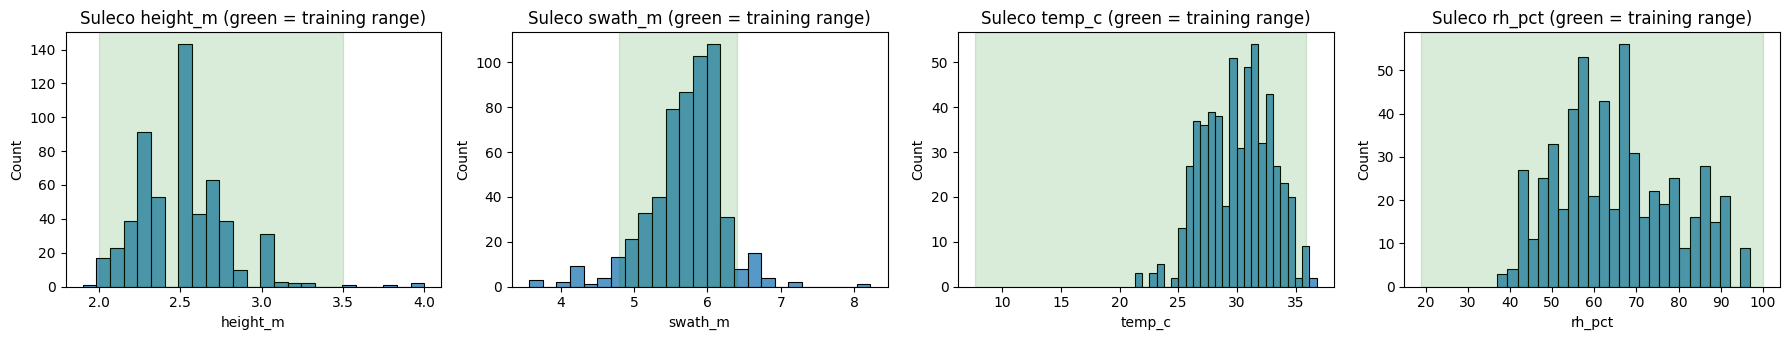

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for i, c in enumerate(["height_m", "swath_m", "temp_c", "rh_pct"]): sns.histplot(m[c], bins=25, ax=ax[i]); ax[i].axvspan(*VALID_RANGES[c], color="green", alpha=0.15); ax[i].set_title(f"Suleco {c} (green = training range)")
plt.tight_layout(); plt.savefig("fig_b4_coverage.png", dpi=150, bbox_inches="tight"); plt.show()

## B5 – Predicted drift for real Suleco flights
Suleco records have no flight heading and no droplet setting.
So for each flight we try 36 headings (0°–350°) and keep the best (min), typical (median) and worst (max) drift,
for three droplet classes (VF-F, F-M, C-VC).

In [7]:
v = m[m["in_range"]].copy()
headings = np.arange(0, 360, 10)

def drift_all_headings(cls):
    preds = []
    for h in headings:
        cw = v["wind_2m_ms"] * np.abs(np.sin(np.radians(v["wind_dir_deg"] - h)))
        X = pd.DataFrame({"crosswind_ms": np.clip(cw, 0.5, 6.7), "height_m": v["height_m"], "swath_m": v["swath_m"], "temp_c": v["temp_c"], "rh_pct": v["rh_pct"], "droplet_code": DROPLET_CODE[cls]})
        preds.append(model.predict(X[FEATURES]))
    P = np.vstack(preds)
    return P.min(axis=0), np.median(P, axis=0), P.max(axis=0)

for cls in ["VF-F", "F-M", "C-VC"]:
    v[f"min_{cls}"], v[f"typ_{cls}"], v[f"max_{cls}"] = drift_all_headings(cls)

print("flights predicted:", len(v))
v.filter(regex="^(min|typ|max)_").describe().round(1).T

flights predicted: 503


,count,mean,std,min,25%,50%,75%,max
min_VF-F,503.0,27.5,6.0,17.0,23.0,26.1,32.0,45.7
typ_VF-F,503.0,35.8,9.7,19.0,29.0,34.7,41.3,59.4
max_VF-F,503.0,39.6,11.7,19.0,31.5,37.4,47.9,65.0
min_F-M,503.0,13.0,0.6,11.8,12.5,12.9,13.3,16.0
typ_F-M,503.0,19.4,7.0,11.8,14.1,16.8,22.4,36.8
max_F-M,503.0,22.7,8.8,11.8,16.0,19.8,28.3,42.4
min_C-VC,503.0,8.4,0.4,7.6,8.1,8.4,8.6,9.7
typ_C-VC,503.0,11.9,3.3,7.6,9.2,11.5,13.4,21.6
max_C-VC,503.0,13.5,4.2,7.6,10.9,12.4,15.6,25.7


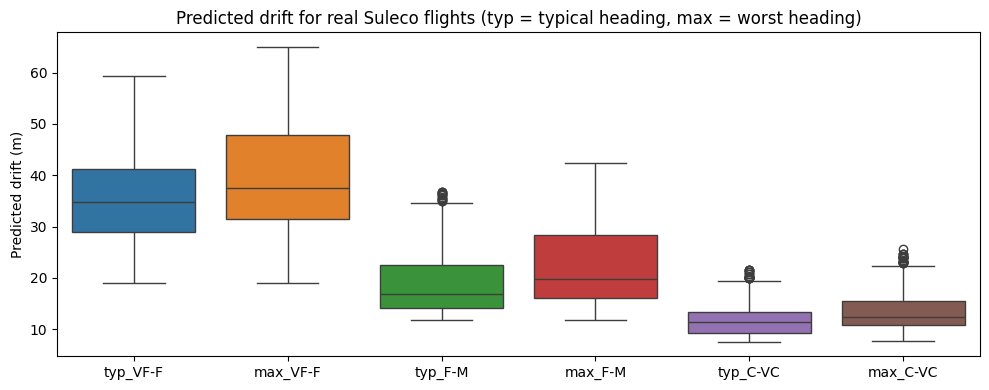

In [8]:
cols = ["typ_VF-F", "max_VF-F", "typ_F-M", "max_F-M", "typ_C-VC", "max_C-VC"]
plt.figure(figsize=(10, 4))
sns.boxplot(data=v[cols])
plt.ylabel("Predicted drift (m)")
plt.title("Predicted drift for real Suleco flights (typ = typical heading, max = worst heading)")
plt.tight_layout()
plt.savefig("fig_b6_suleco_drift.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
print("Share of flights with worst-case drift > 30 m (%):")
print(((v[["max_VF-F", "max_F-M", "max_C-VC"]] > 30).mean() * 100).round(1))
v.groupby("district")[["wind_2m_ms", "typ_F-M", "max_F-M"]].median().round(1)

Share of flights with worst-case drift > 30 m (%):
max_VF-F    78.5
max_F-M     22.9
max_C-VC     0.0
dtype: float64


,wind_2m_ms,typ_F-M,max_F-M
district,,,
Ampara,1.4,16.700001,19.799999
Badulla,1.0,15.200000,17.700001
Polonnaruwa,4.5,31.900000,37.400002


In [10]:
v[["district", "start", "height_m", "swath_m", "speed_ms", "temp_c", "rh_pct", "wind_2m_ms"] + cols].round(2).to_csv("suleco_predicted_drift_summary.csv", index=False)
print("saved")

saved
